##### Copyright 2026 The Contributors

Licensed under the Apache License, Version 2.0 (the "License");
you may not use this file except in compliance with the License.
See the LICENSE file in the repository root.


# 01 — Feature engineering

Build the hexagon x month feature table. Rather than hiding everything behind
one function call, this notebook walks through **each feature family
separately** so you can see exactly what is computed and inspect the output
at every step -- and swap out or extend any single step without touching the
rest.

## Prerequisites
- Run notebook `00` first (creates `sample_data/patients.csv` + `hexagons.csv`)


In [1]:
import sys
from pathlib import Path

# Make `pipeline` / `utils` importable when Jupyter's cwd is notebooks/
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
print("ROOT =", ROOT)


ROOT = /Users/froncort.ai/Desktop/Froncort/ai-acf-ml-notebooks


In [2]:
from utils import SAMPLE_DATA_DIR, ARTIFACTS_DIR, load_data, save_data, ensure_dirs

ensure_dirs()
DATA_DIR = SAMPLE_DATA_DIR  # point this at your own folder if not using notebook 00's output

patients = load_data(DATA_DIR / "patients.csv")
hexagons = load_data(DATA_DIR / "hexagons.csv")
contacts_path = DATA_DIR / "contacts.csv"
contacts = load_data(contacts_path) if contacts_path.exists() else None

patients["diagnosis_date"] = pd.to_datetime(patients["diagnosis_date"], errors="coerce")
print(f"patients={len(patients)}  hexagons={len(hexagons)}  contacts={0 if contacts is None else len(contacts)}")
patients.head()


patients=6795  hexagons=300  contacts=1200


,patient_id,h3_index,diagnosis_date,age,site_of_disease,hiv_status,diabetes_status,is_recidivism,infectivity_score
0,P00000,8a60885010cffff,2024-01-17,67,Pulmonary,Negative,Yes,0,1.0
1,P00001,8a60885010cffff,2024-01-25,54,Extra-pulmonary,Negative,No,0,0.2
2,P00002,8a60885010cffff,2024-01-17,44,Other,Negative,Yes,0,0.2
3,P00003,8a60885010d7fff,2024-01-12,64,Pulmonary,Negative,No,0,1.0
4,P00004,8a60885010dffff,2024-01-04,27,Pulmonary,Negative,No,0,1.0


## Step 1 — the hexagon x month grid

Every downstream feature is computed on a **complete** grid: every hexagon,
crossed with every month in the data's date range -- including hexagons that
had zero cases in a given month. This is essential: a model that only ever
sees rows with cases can never learn what "quiet before an outbreak" looks
like, because it never sees the negative class.


In [3]:
from pipeline.features import create_monthly_grid

grid = create_monthly_grid(patients, hexagons)
print(f"Grid: {len(grid)} hexagon-months = {hexagons['h3_index'].nunique()} hexagons x {grid['month'].nunique()} months")
grid.head()


INFO | Grid: 6000 hex-months (300 hex × 20 months)


Grid: 6000 hexagon-months = 300 hexagons x 20 months


,h3_index,month,year,month_num
0,8a60885010c7fff,2024-01-01,2024,1
1,8a60885010c7fff,2024-02-01,2024,2
2,8a60885010c7fff,2024-03-01,2024,3
3,8a60885010c7fff,2024-04-01,2024,4
4,8a60885010c7fff,2024-05-01,2024,5


## Step 2 — clinical features

Case counts, comorbidity proxies, and an infectivity-weighted load (pulmonary
cases weighted higher since they drive most airborne transmission).


In [4]:
from pipeline.features import calculate_clinical_features

grid = calculate_clinical_features(patients, grid)
print("New columns:", [c for c in grid.columns if c not in ["h3_index", "month", "year", "month_num"]])
grid[["h3_index", "month", "total_cases", "pulmonary_cases", "hiv_positive_count", "weighted_infectivity_load"]].describe()


New columns: ['total_cases', 'avg_age', 'pulmonary_cases', 'relapse_rate', 'hiv_positive_count', 'diabetes_count', 'weighted_infectivity_load', 'pulmonary_percentage']


,month,total_cases,pulmonary_cases,hiv_positive_count,weighted_infectivity_load
count,6000,6000.000000,6000.000000,6000.000000,6000.000000
mean,2024-10-16 00:00:00,1.132500,0.778667,0.059500,0.849433
min,2024-01-01 00:00:00,0.000000,0.000000,0.000000,0.000000
25%,2024-05-24 06:00:00,0.000000,0.000000,0.000000,0.000000
50%,2024-10-16 12:00:00,1.000000,1.000000,0.000000,1.000000
75%,2025-03-08 18:00:00,2.000000,1.000000,0.000000,1.200000
max,2025-08-01 00:00:00,8.000000,6.000000,2.000000,6.400000
std,NaN,1.205482,0.973911,0.247595,0.993925


In [5]:
# Sanity check: total_cases summed over the grid must equal total patients
# (every patient should land in exactly one hexagon-month)
assert grid["total_cases"].sum() == len(patients), "case count mismatch -- check date/H3 parsing upstream"
print("OK: grid total_cases sums to", int(grid["total_cases"].sum()), "== len(patients)")


OK: grid total_cases sums to 6795 == len(patients)


## Step 3 — temporal features

Lags (T-1..T-3), rolling sums/means, month-over-month trend, persistence
(how many of the last 6 months had any case), and days since the last case.
These let the model see momentum, not just a single snapshot.


In [6]:
from pipeline.features import calculate_temporal_features

grid = calculate_temporal_features(grid)
example_hex = grid.loc[grid["total_cases"].idxmax(), "h3_index"]  # a busy hexagon, for illustration
cols = ["month", "total_cases", "cases_t_minus_1", "cases_sum_3mo", "mom_trend", "persistence_score", "days_since_last_case"]
grid[grid["h3_index"] == example_hex][cols].sort_values("month")


,month,total_cases,cases_t_minus_1,cases_sum_3mo,mom_trend,persistence_score,days_since_last_case
4500,2024-01-01,4.0,0.0,4.0,0.0,0,0
4501,2024-02-01,6.0,4.0,10.0,2.0,1,0
4502,2024-03-01,3.0,6.0,13.0,-3.0,2,0
4503,2024-04-01,1.0,3.0,10.0,-2.0,3,0
4504,2024-05-01,0.0,1.0,4.0,-1.0,4,30
4505,2024-06-01,0.0,0.0,1.0,0.0,4,61
4506,2024-07-01,8.0,0.0,8.0,8.0,4,0
4507,2024-08-01,0.0,8.0,8.0,-8.0,4,31
4508,2024-09-01,3.0,0.0,11.0,3.0,3,0
4509,2024-10-01,3.0,3.0,6.0,0.0,3,0


## Step 4 — contact-tracing features (optional)

Zero-filled if you don't have a contact-tracing register -- the pipeline
degrades gracefully rather than failing.


In [7]:
from pipeline.features import calculate_contact_features

grid = calculate_contact_features(contacts, grid)
print("n_contacts present:", "n_contacts" in grid.columns, "| non-zero rows:", (grid["n_contacts"] > 0).sum())


n_contacts present: True | non-zero rows: 1200


## Step 5 — spatial features

Ring-1 H3 neighbor case load (an outbreak spilling into a hexagon from next
door is a strong early signal) and any vulnerability/density covariate from
the hexagons table (e.g. slum density). Uses the real `h3` library when
installed; falls back to a lat/lng proximity approximation otherwise.


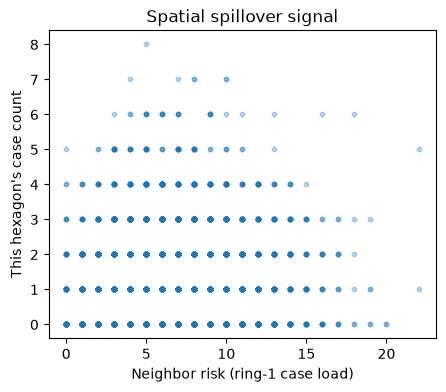

In [8]:
from pipeline.features import calculate_spatial_features

grid = calculate_spatial_features(grid, hexagons)
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(grid["neighbor_risk_ring1"], grid["total_cases"], alpha=0.3, s=10)
ax.set_xlabel("Neighbor risk (ring-1 case load)")
ax.set_ylabel("This hexagon's case count")
ax.set_title("Spatial spillover signal")
plt.show()


## Step 6 — interaction features

Simple products that let a tree model split on combined risk factors
(e.g. high slum density AND high neighbor risk) more easily than on either
alone.


In [9]:
from pipeline.features import calculate_interaction_features

grid = calculate_interaction_features(grid)
save_data(grid, ARTIFACTS_DIR / "features.csv")
print(f"Final feature table: {grid.shape[0]} rows x {grid.shape[1]} columns")
grid.columns.tolist()


INFO | Saved 6000 rows -> /Users/froncort.ai/Desktop/Froncort/ai-acf-ml-notebooks/artifacts/features.csv


Final feature table: 6000 rows x 29 columns


['h3_index',
 'month',
 'year',
 'month_num',
 'total_cases',
 'avg_age',
 'pulmonary_cases',
 'relapse_rate',
 'hiv_positive_count',
 'diabetes_count',
 'weighted_infectivity_load',
 'pulmonary_percentage',
 'cases_t_minus_1',
 'cases_t_minus_2',
 'cases_t_minus_3',
 'cases_sum_3mo',
 'cases_3month_rolling_avg',
 'cases_sum_6mo',
 'mom_trend',
 'persistence_score',
 'days_since_last_case',
 'n_contacts',
 'slum_density',
 'neighbor_risk_ring1',
 'hotspot_encirclement',
 'cases_x_slum',
 'neighbor_x_slum',
 'lag1_x_persistence',
 'transmission_vulnerability_score']

## Full pipeline in one call

Everything above is also available as a single function, `build_feature_table`,
for when you don't need the step-by-step inspection (e.g. batch re-runs).


In [10]:
from pipeline.features import build_feature_table

features_oneshot = build_feature_table(patients, hexagons, contacts)
pd.testing.assert_frame_equal(
    features_oneshot.reset_index(drop=True), grid.reset_index(drop=True), check_dtype=False
)
print("OK: build_feature_table() matches the step-by-step result exactly.")


INFO | Grid: 6000 hex-months (300 hex × 20 months)


INFO | Feature table ready: 6000 rows, 29 cols


OK: build_feature_table() matches the step-by-step result exactly.


## Correlation check

A quick look at which engineered features correlate most with the *current*
case count -- useful for spotting obviously redundant features before
modeling (not a leakage check; that happens in notebook `03` against the
*future* target).


In [11]:
numeric_cols = grid.select_dtypes("number").columns.drop(["year", "month_num"], errors="ignore")
corr = grid[numeric_cols].corr()["total_cases"].sort_values(ascending=False)
corr.head(15)


total_cases                         1.000000
cases_x_slum                        0.931477
weighted_infectivity_load           0.915933
pulmonary_cases                     0.859001
cases_3month_rolling_avg            0.699726
cases_sum_3mo                       0.665751
transmission_vulnerability_score    0.635859
mom_trend                           0.616088
pulmonary_percentage                0.532243
cases_sum_6mo                       0.496268
slum_density                        0.423674
diabetes_count                      0.369378
neighbor_x_slum                     0.353657
hiv_positive_count                  0.243893
cases_t_minus_1                     0.200202
Name: total_cases, dtype: float64